In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
image=cv2.imread(r"C:\Users\snaha\Desktop\image_processing\Lenna_(test_image).png",1)
if image is None:
    print("Image not found!")
else:
    print("Image loaded successfully.")

Image not found!


Binary Image:
[[0 0 0 0 0]
 [0 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]


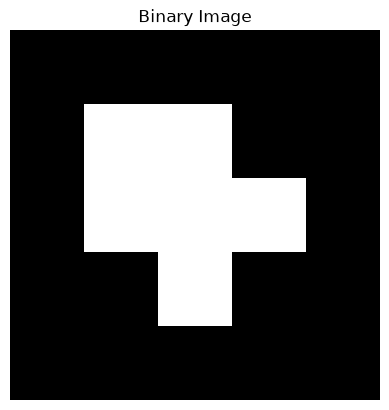

In [3]:
binary_image = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0]
])

print("Binary Image:")
print(binary_image)

plt.imshow(binary_image, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()

In [4]:
def get_4_neighbors(image, r, c):
    rows, cols = image.shape
    
    positions = [
        (r-1, c),  
        (r+1, c),  
        (r, c-1),  
        (r, c+1)   
    ]
    
    neighbors = []
    
    for nr, nc in positions:
        if 0 <= nr < rows and 0 <= nc < cols:
            neighbors.append((nr, nc))
    
    return neighbors

In [5]:
pixel = (2, 2)

print("4-neighbours of", pixel, ":")
print(get_4_neighbors(binary_image, pixel[0], pixel[1]))

4-neighbours of (2, 2) :
[(1, 2), (3, 2), (2, 1), (2, 3)]


In [6]:
def get_8_neighbors(image, r, c):
    rows, cols = image.shape
    
    neighbors = []
    
    for dr in [-1, 0, 1]:
        for dc in [-1, 0, 1]:
            
            if dr == 0 and dc == 0:
                continue
            
            nr = r + dr
            nc = c + dc
            
            if 0 <= nr < rows and 0 <= nc < cols:
                neighbors.append((nr, nc))
    
    return neighbors

In [7]:
print("8-neighbours of", pixel, ":")
print(get_8_neighbors(binary_image, pixel[0], pixel[1]))

8-neighbours of (2, 2) :
[(1, 1), (1, 2), (1, 3), (2, 1), (2, 3), (3, 1), (3, 2), (3, 3)]


In [11]:
import numpy as np

# Binary image
image = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 0, 1, 0],
    [0, 0, 0, 0, 0]
])

def m_connected(image, p, q):

    r1, c1 = p
    r2, c2 = q

    # Both pixels must be 1
    if image[r1, c1] != 1 or image[r2, c2] != 1:
        return False

    # 4-neighbour
    if abs(r1-r2) + abs(c1-c2) == 1:
        return True

    # Diagonal neighbour
    if abs(r1-r2) == 1 and abs(c1-c2) == 1:

        common = [
            (r1, c2),
            (r2, c1)
        ]

        # If common 4-neighbours are not 1,
        # diagonal connection is allowed
        for rr, cc in common:
            if image[rr, cc] == 1:
                return False

        return True

    return False


p = (1, 1)
q = (2, 2)

print("Pixel P:", p)
print("Pixel Q:", q)
print("m-connected:", m_connected(image, p, q))

Pixel P: (1, 1)
Pixel Q: (2, 2)
m-connected: False


In [15]:
import math

p = (1, 1)
q = (3, 3)
 
euclidean = math.sqrt(
    (p[0]-q[0])**2 +
    (p[1]-q[1])**2
)

print("Euclidean distance:", euclidean)
city_block = abs(p[0]-q[0]) + abs(p[1]-q[1])

print("City-block distance:", city_block)

chessboard = max(
    abs(p[0]-q[0]),
    abs(p[1]-q[1])
)

print("Chessboard distance:", chessboard)

Euclidean distance: 2.8284271247461903
City-block distance: 4
Chessboard distance: 2


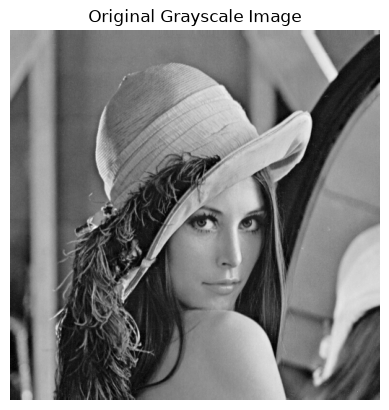

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = 

plt.imshow(image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

In [25]:
dft = np.fft.fft2(image)
print("DFT calculated successfully")



DFT calculated successfully


In [24]:
dft_shift = np.fft.fftshift(dft)


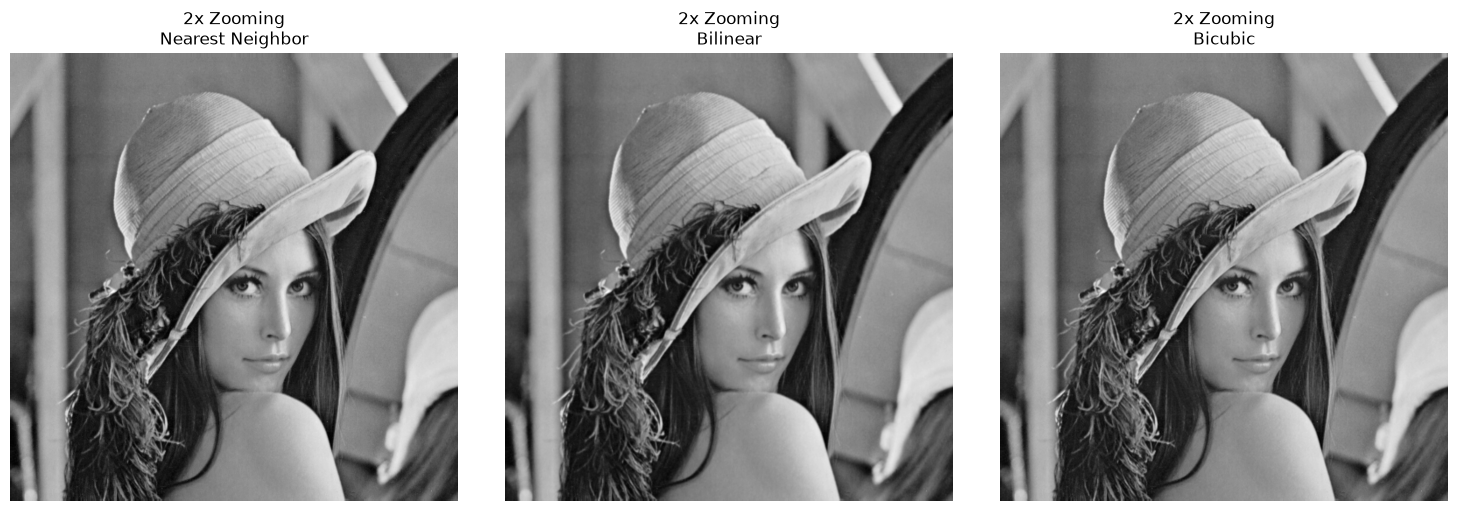

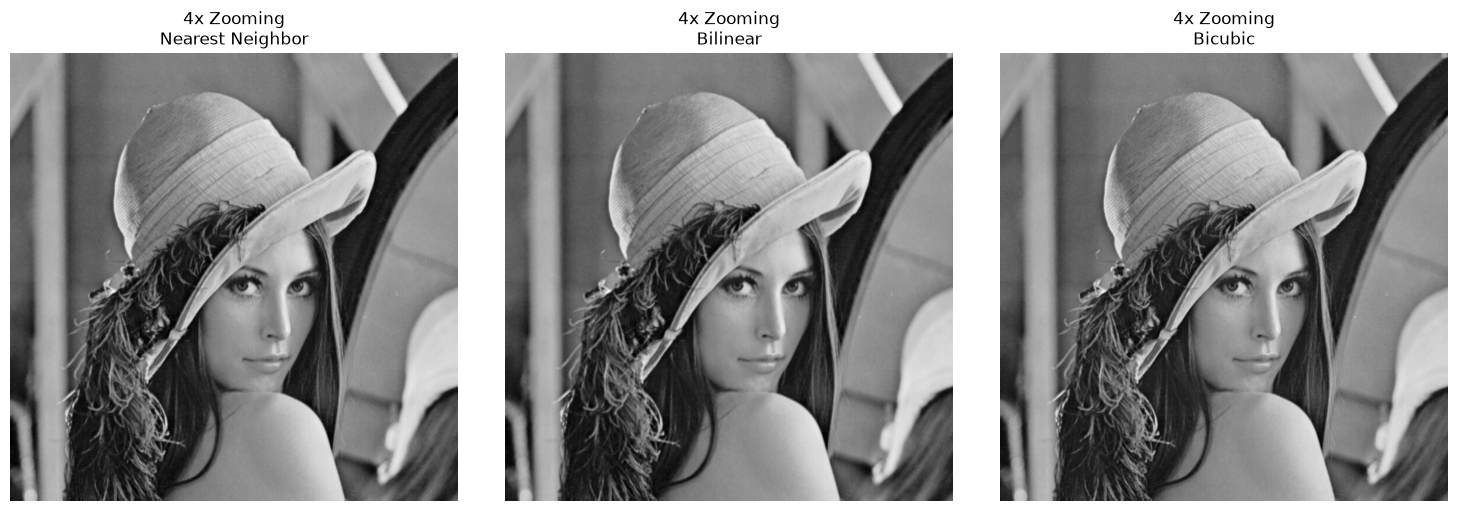

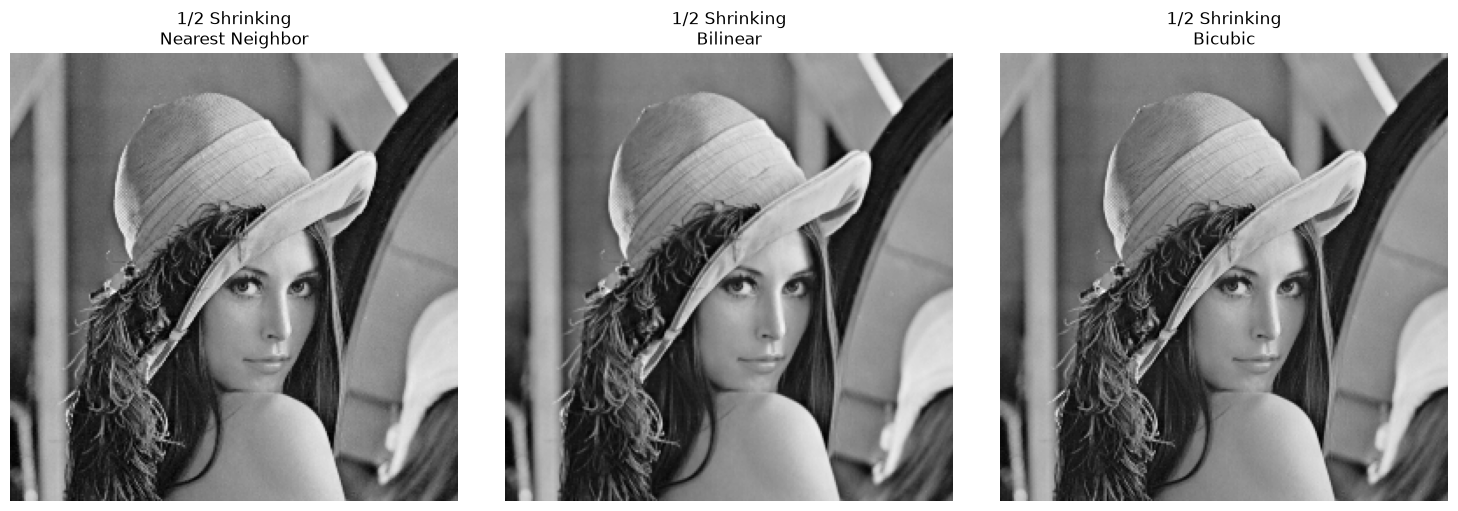

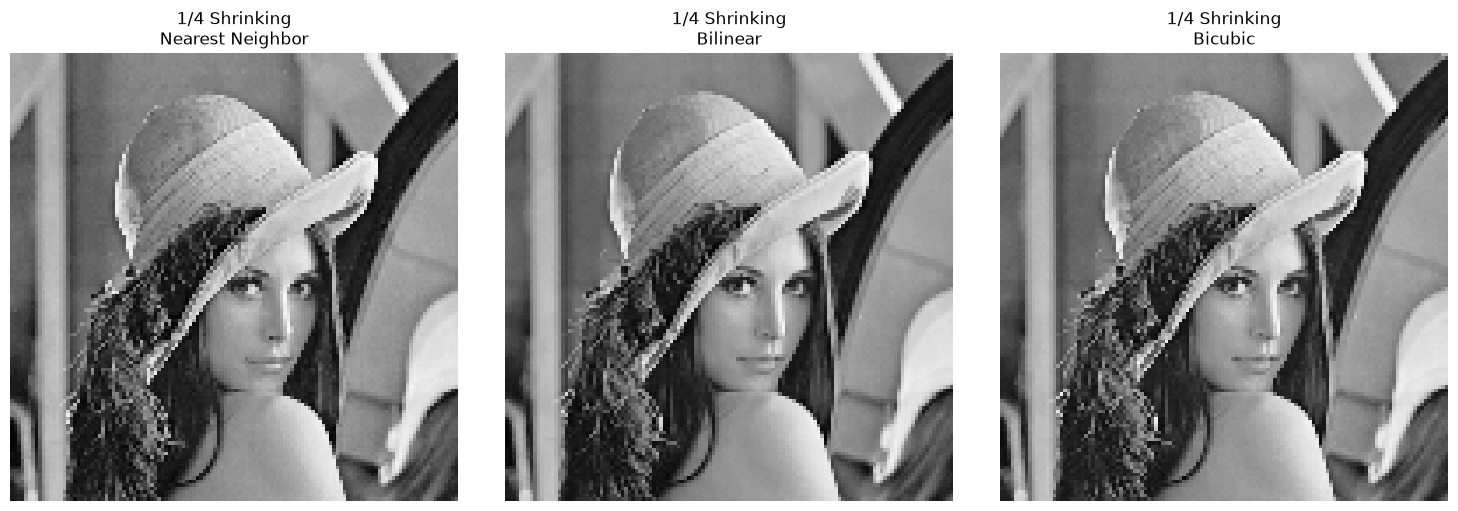

In [27]:
#Session 2 Question 2
img = cv2.imread("Lenna_(test_image).png", cv2.IMREAD_GRAYSCALE)
if img is None:
    print("Image could not be loaded.")
else:
    # a. Nearest-neighbor interpolation
    # b. Bilinear interpolation
    # c. Bicubic interpolation
    methods = {
        "Nearest Neighbor": cv2.INTER_NEAREST,
        "Bilinear": cv2.INTER_LINEAR,
        "Bicubic": cv2.INTER_CUBIC
    }

    scales = {
        "2x Zooming": 2.0,
        "4x Zooming": 4.0,
        "1/2 Shrinking": 0.5,
        "1/4 Shrinking": 0.25
    }

    for scale_name, scale in scales.items():
        results = []

        for method_name, interpolation in methods.items():
            resized = cv2.resize(
                img,
                None,
                fx=scale,
                fy=scale,
                interpolation=interpolation
            )

            results.append((method_name, resized))

        plt.figure(figsize=(15, 5))

        for i, (method_name, image) in enumerate(results):
            plt.subplot(1, 3, i + 1)
            plt.imshow(image, cmap="gray")
            plt.title(scale_name + "\n" + method_name)
            plt.axis("off")

        plt.tight_layout()
        plt.show()

DFT calculated successfully.

DCT Coefficient Matrix:
[[67802.77 -4509.06 -1224.41 ...    -2.42    -5.93   -11.81]
 [ 3746.28  4035.49 -2709.3  ...     3.1      7.78    12.08]
 [   62.45  1193.14 -3032.15 ...    -3.97    -5.46     1.37]
 ...
 [    0.15    -2.63    -1.2  ...    -1.43     2.16     1.03]
 [    2.21    -1.14     1.64 ...    -0.32     0.43     2.02]
 [   -1.72     0.59    -2.02 ...     0.47     1.09     0.12]]


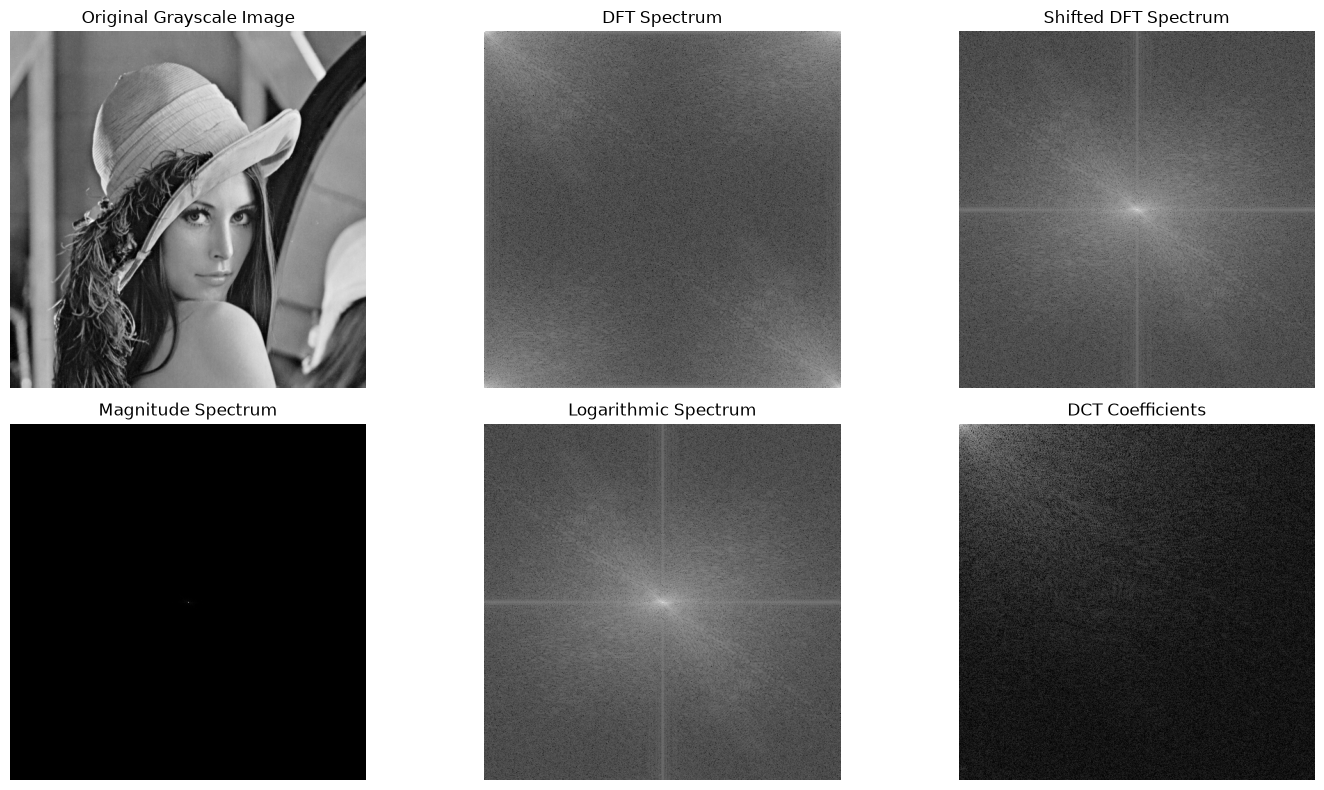

In [1]:
#Session 3 question 2

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("Lenna_(test_image).png", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found.")
    exit()

# --------------------------------------------------
# a. Calculate 2-D Discrete Fourier Transform (DFT)
# --------------------------------------------------

dft = np.fft.fft2(img)

print("DFT calculated successfully.")

# --------------------------------------------------
# b. Shift zero-frequency component to center
# --------------------------------------------------

dft_shifted = np.fft.fftshift(dft)

# --------------------------------------------------
# c. Calculate magnitude spectrum
# --------------------------------------------------

magnitude = np.abs(dft_shifted)

# --------------------------------------------------
# d. Apply logarithmic scaling
# --------------------------------------------------

log_magnitude = np.log(1 + magnitude)

# Normalize for display
log_magnitude_display = cv2.normalize(
    log_magnitude,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

log_magnitude_display = np.uint8(log_magnitude_display)

# --------------------------------------------------
# e. Calculate 2-D Discrete Cosine Transform (DCT)
# --------------------------------------------------

img_float = np.float32(img)

dct = cv2.dct(img_float)

# --------------------------------------------------
# f. Display DCT coefficient matrix
# --------------------------------------------------

print("\nDCT Coefficient Matrix:")
np.set_printoptions(precision=2, suppress=True)
print(dct)


# --------------------------------------------------
# Display results
# --------------------------------------------------

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(np.log(1 + np.abs(dft)), cmap="gray")
plt.title("DFT Spectrum")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(np.log(1 + np.abs(dft_shifted)), cmap="gray")
plt.title("Shifted DFT Spectrum")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(magnitude, cmap="gray")
plt.title("Magnitude Spectrum")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(log_magnitude_display, cmap="gray")
plt.title("Logarithmic Spectrum")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(np.log(1 + np.abs(dct)), cmap="gray")
plt.title("DCT Coefficients")
plt.axis("off")

plt.tight_layout()
plt.show()

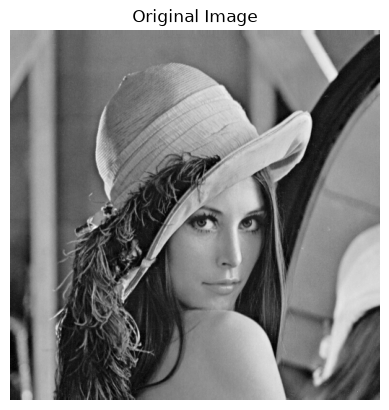

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("Lenna_(test_image).png", cv2.IMREAD_GRAYSCALE)

plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

In [4]:
dft = np.fft.fft2(image) ##dft contains both magnitude and phase information, and both are needed to reconstruct the image.

In [5]:
reconstructed = np.fft.ifft2(dft)

In [6]:
reconstructed = np.real(reconstructed)

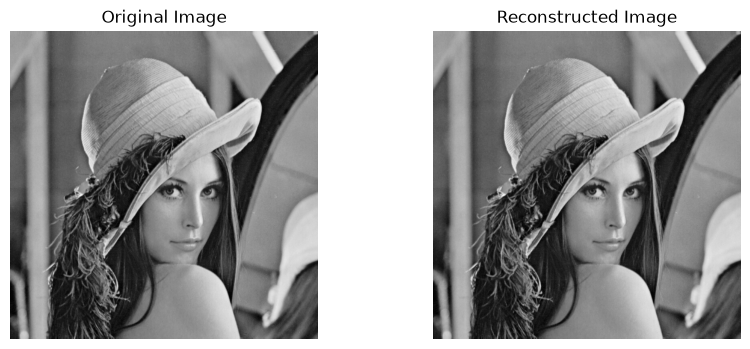

In [8]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed, cmap="gray")
plt.title("Reconstructed Image")
plt.axis("off")

plt.show()